## Start-to-end tracking on the RCS chain

In [1]:
import xobjects as xo
import xtrack as xt
import xpart as xp
import sys
import json
import xplt
import numpy as np
import matplotlib.pyplot as plt
import scipy.constants as sc
from rcsparameters.ring_geometry.ring_geometry import RingGeometry 
sys.path.append('/mnt/c/muco/code')
from ramping_module import generate_particles, ramping, launch_tracking, launch_tracking_mon


/mnt/c/muco/venv/lib/python3.11/site-packages/numpy/_core/getlimits.py:551: UserWarning: Signature b'\x00\xd0\xcc\xcc\xcc\xcc\xcc\xcc\xfb\xbf\x00\x00\x00\x00\x00\x00' for <class 'numpy.longdouble'> does not match any known type: falling back to type probe function.
This warnings indicates broken support for the dtype!
  machar = _get_machar(dtype)
/mnt/c/muco/venv/lib/python3.11/site-packages/xplt/hooks.py:33: RuntimeWarning: Failed to register formatters with pint: No module named 'pint'
  warnings.warn(f"Failed to register formatters with pint: {e}", RuntimeWarning)


Input parameters

In [2]:
nemitt_x_0 = 25e-6
nemitt_y_0 = 25e-6
emit_s = 0.025
n_part = 1000
RF_tuner = False
adapt_ho_delta = True
list_file_line = [
    '/mnt/c/muco/code/lattice/RCS1_DS_inj_5nc.json',
    '/mnt/c/muco/code/lattice/RCS2_DS_inj.json',
    '/mnt/c/muco/code/lattice/RCS3_DS_inj.json',
    '/mnt/c/muco/code/lattice/RCS4_DS_inj.json'
]
list_geo_file = [
    '/mnt/c/muco/code/notebook_optics/para_RCS1_opt_5nc.json',
    '/mnt/c/muco/code/notebook_optics/para_RCS2_opt.json',
    '/mnt/c/muco/code/notebook_optics/para_RCS3_opt.json',
    '/mnt/c/muco/code/notebook_optics/para_RCS4_opt.json'
]
list_n_turn = [17,
               55
             ,66,55
             ]


In [3]:
# list_file_line = [
#     '/mnt/c/muco/code/lattice_consolidated_ESPPU/GF_RCS1/line_RCS1_gf_normal_qp_8_arc.json',
#     '/mnt/c/muco/code/lattice_consolidated_ESPPU/GF_RCS2/line_RCS2_gf_normal_qp_8_arc.json',
#     '/mnt/c/muco/code/lattice_consolidated_ESPPU/GF_RCS3/line_RCS3_gf_normal_qp_8_arc.json',
#     '/mnt/c/muco/code/lattice_consolidated_ESPPU/GF_RCS4/line_RCS4_gf_normal_qp_8_arc.json'
# ]
# list_geo_file = [
#     '/mnt/c/muco/code/lattice_consolidated_ESPPU/GF_RCS1/para_RCS1_gf_normal_qp__8_arc.json',
#     '/mnt/c/muco/code/lattice_consolidated_ESPPU/GF_RCS2/para_RCS2_gf_normal_qp__8_arc.json',
#     '/mnt/c/muco/code/lattice_consolidated_ESPPU/GF_RCS3/para_RCS3_gf_normal_qp__8_arc.json',
#     '/mnt/c/muco/code/lattice_consolidated_ESPPU/GF_RCS4/para_RCS4_gf_normal_qp__8_arc.json'
# ]
# list_n_turn = [17, 
#              55, 66, 55
#             ]

In [4]:
# line = xt.Line.from_json('/mnt/c/muco/code/lattice_consolidated_ESPPU/GF_RCS2/line_RCS2_gf_normal_qp_8_arc.json')
# tw = line.twiss(matrix_stability_tol=0.1, compute_chromatic_properties=True)
# print(tw.qx, tw.qy)

In [5]:
# # line = xt.Line.from_json('/mnt/c/muco/code/lattice_consolidated_ESPPU/GF_RCS1/line_RCS1_gf_normal_qp_8_arc.json')
# line = xt.Line.from_json('/mnt/c/muco/code/lattice_consolidated_ESPPU/line_RCS1_gf_normal_qp_8_arc_v3.json')

# tw = line.twiss(matrix_stability_tol=0.1, compute_chromatic_properties=True)

# print(tw.qy)
# i_a = 5 + 3
# for i in np.arange(0,i_a+1):
#     line.vars[f'k{i+1}'] = line[f'qp{i+1}_l'].k1
#     line.element_refs[f'qp{i+1}_l'].k1 = line.vars[f'k{i+1}']
#     line.element_refs[f'qp{i+1}_r'].k1 = line.vars[f'k{i+1}']

#     print(f'qp{i+1}', f'k{i+1}')

# qx = 5.235
# qy = 5.234
# matcher = line.match(
#         vary = [xt.VaryList([
#             'k1', 'k2', 'k3',
#             'k4', 'k5', 
#             ], step=1e-8, tag='quad')],
#         targets= [xt.TargetSet(dx=0, at=0, tol=1e-9),
#                   xt.TargetSet(qx=qx, qy=qy, tol=1e-9)],
#         method='6d',
#         solve=True,
#         matrix_stability_tol=0.1
#         )

# tw = line.twiss(matrix_stability_tol=0.1, compute_chromatic_properties=True)
# from generate_fodo import plot_twiss
# plot_twiss(tw)
# line.to_json('/mnt/c/muco/code/line_RCS1_gf_normal_qp_8_arc_matched.json')


In [6]:
# list_file_line[0] = '/mnt/c/muco/code/line_RCS1_gf_normal_qp_8_arc_matched.json'
# # list_file_line[0] = '/mnt/c/muco/code/lattice_consolidated_ESPPU/line_RCS1_gf_normal_qp_8_arc_v3.json'
# list_geo_file[0] = '/mnt/c/muco/code/lattice_consolidated_ESPPU/para_RCS1_gf_normal_qp__8_arc_v3.json'

In [7]:
def calculate_transmission_cumul(particles, total_particles, n_turn, cumulative_lost_particles=0):
    particles.unhide_lost_particles()
    lost_turns = sorted(particles.at_turn[particles.state < 0])
    particles.hide_lost_particles()
    transmissions = []
    lost_particles = cumulative_lost_particles  # Start with any previously lost particles
    for turn in range(1, n_turn + 1):
        if turn in lost_turns:
            lost_particles += lost_turns.count(turn)
        transmission = (total_particles - lost_particles) / total_particles
        transmissions.append(transmission)
    return transmissions, lost_particles

In [8]:
def transfer_matrix(tw0, tw1, particles):

    Ax = np.sqrt(tw1.betx[0]/tw0.betx[0])
    Bx = (tw0.alfx[0]-tw1.alfx[0])/np.sqrt(tw0.betx[0]*tw1.betx[0])
    Ay = np.sqrt(tw1.bety[0]/tw0.bety[0])
    By = (tw0.alfy[0]-tw1.alfy[0])/np.sqrt(tw0.bety[0]*tw1.bety[0])

    particles.px = Bx*particles.x + particles.px/Ax 
    particles.x = Ax*particles.x  
    particles.py = By*particles.y + particles.py/Ay
    particles.y = Ay*particles.y


In [9]:
def calc_separatrix(line, rcs, tw, particles, title = None):
        h_rf = np.round(1.3e9*tw.T_rev0*rcs.nb_arc)
        energy = particles.p0c[0]
        # print('energy', energy)
        phase = line['cavity'].lag
        # print('phase', phase)
        energy_increment_per_arc = line['RF_acc'].Delta_p0c*2
        # print('energy incr', energy_increment_per_arc)
        volt_arc = line['cavity'].voltage*2

        #RF bucket defined here on RCS => careful with consistency!!
        machine_rf_bucket = xp.longitudinal.rf_bucket.RFBucket(
                circumference = rcs.circumference/rcs.nb_arc,
                gamma = energy/xp.MUON_MASS_EV, mass_kg = sc.physical_constants['muon mass'][0],
                charge_coulomb = sc.e, alpha_array = [tw.momentum_compaction_factor], 
                p_increment = energy_increment_per_arc * sc.e / sc.c, 
                harmonic_list = [h_rf/rcs.nb_arc], voltage_list = [volt_arc], 
                phi_offset_list = np.atleast_1d((phase)*np.pi/180),
                z_offset = None
                )
        xx = np.linspace(machine_rf_bucket.z_left, machine_rf_bucket.z_right, 1000)
        yy = machine_rf_bucket.separatrix(xx)

        plt.figure()
        plt.title(title)    
        plt.scatter(particles.zeta, particles.delta*particles.p0c/1e9, label='Particle distribution', s=2)
        plt.plot((xx-machine_rf_bucket.z_sfp), yy*energy/1e9, color='tab:orange', label='RF bucket')
        plt.plot((xx-machine_rf_bucket.z_sfp), -yy*energy/1e9, color='tab:orange')
        plt.xlabel('z [m]')
        plt.ylabel(r'$\Delta E$ [GeV]')
        plt.legend()
        plt.show()
        return (machine_rf_bucket)

RCS 0


Loading line from dict: 100%|██████████| 82/82 [00:00<00:00, 14362.86it/s]


Done loading line from dict.           
Generate initial particle distribution
The line already has an associated tracker
*** Maximum RMS emittance 0.862958882251387eV s.
... distance to target emittance: -3.10e-01
... distance to target emittance: 4.59e-01
... distance to target emittance: 3.15e-01
... distance to target emittance: 1.04e-01
... distance to target emittance: 9.32e-03
... distance to target emittance: -6.38e-04
... distance to target emittance: 3.76e-06
... distance to target emittance: 1.45e-09
... distance to target emittance: -1.53e-06
--> Emittance: 0.3141592668134178
--> Bunch length: 0.009117882467428763
[ 8.47561363 13.76773091 18.21961599  9.69434671  9.06665007 42.45975808
 22.10694696 23.88603585 13.24219089 18.10224124 15.50440009 19.96580913
 11.53787494 19.87628822 14.30636032 15.61205168 19.02966358  8.72805274
 20.80475201 19.75901751 12.47029053 17.93518678 16.62179898 13.34959885
 24.34569373 26.44393746  8.15182034 13.07064974  8.51928628 12.47484328
 

Tracking: 100%|██████████| 600/600 [00:09<00:00, 66.31it/s] 


Tracking over
RCS 1


Loading line from dict: 100%|██████████| 100/100 [00:00<00:00, 20840.23it/s]

... (10 outputs left out)

Done loading line from dict.           
0
1
2
3
4
5
build tracker


Compiling ContextCpu kernels...
Done compiling ContextCpu kernels.
tracker built
Start tracking


Tracking: 100%|██████████| 1500/1500 [00:20<00:00, 72.72it/s] 


Tracking over


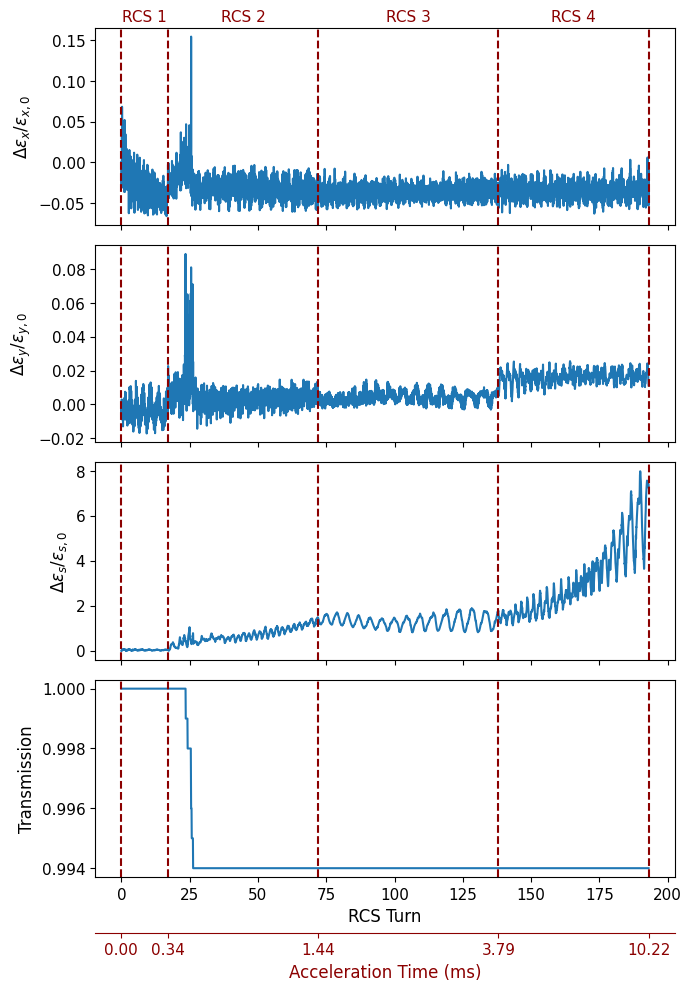

In [10]:
plot=True
# n_part=10000
rec_rcs = []

# Lists to store the concatenated data from all RCS
all_x_mean, all_y_mean = [], []
all_eps_x_per, all_eps_y_per, all_eps_s_per = [], [], []
all_sig_z, all_transmission = [], []
all_turns = []
t_acc = 0
all_t_acc = [0]

rcs_boundaries = np.insert(np.cumsum(list_n_turn), 0, 0)
cumulative_turns = 0
cumulative_lost_particles = 0  # Track cumulative lost particles across RCS

for i_RCS, (line_file, geo_file, turn_rcs) in enumerate(zip(list_file_line, list_geo_file, list_n_turn)):
    print(f'RCS {i_RCS}')
    # Load the line and geometry
    line = xt.Line.from_json(line_file)
    with open(geo_file, 'r') as file:
        para_file = json.load(file)
    rcs = RingGeometry(para_file)
    nb_turn_arc = turn_rcs * rcs.nb_arc
    tw = line.twiss(method='6d', matrix_stability_tol=0.1, compute_chromatic_properties=True)
    
    t_acc += rcs.circumference*turn_rcs/sc.c
    all_t_acc.append(t_acc)
    
    # Generate particles for the first RCS only
    if i_RCS == 0:
        print('Generate initial particle distribution')
        particles = generate_particles(rcs = rcs, line = line, tw = tw, 
                                    n_part = n_part, n_turn_rcs = turn_rcs, 
                                    e_x = nemitt_x_0, e_y = nemitt_y_0, 
                                    e_s = emit_s, adapt = adapt_ho_delta)
        particles_injection = particles.copy()
        
    # Apply transfer matrix from RCSi to RCSi+1 to particle distribution 
    else:
        particles0=particles.copy()
        mask_lost = particles0.state > 0
        particles=xp.Particles(
                mass0=xp.MUON_MASS_EV, q0=1, p0c=particles0.p0c[mask_lost][0],
                x=particles0.x[mask_lost], px=particles0.px[mask_lost], 
                y=particles0.y[mask_lost], py=particles0.py[mask_lost],
                zeta=particles0.zeta[mask_lost], delta=particles0.delta[mask_lost]
                )
        transfer_matrix(tw_previous, tw, particles)

    # particles.hide_lost_particles()
    # Plot particle distribution and RF bucket at injection 
    # calc_separatrix(line=line, rcs=rcs, tw=tw, particles=particles,
    #             title= f'RF bucket at injection in RCS{i_RCS+1}')
    
    # Apply ramping for the current RCS
    ramping(rcs, line, method='var_k', t_ref=0, n_turn_rcs=nb_turn_arc, RF_tuning=RF_tuner)

    # Track for the current RCS
    track_res, rec = launch_tracking_mon(line = line, tw = tw, n_turn_rcs = turn_rcs, 
                    nb_turn_arc = nb_turn_arc, particles = particles, n_part=n_part, plot=False)
    x_mean, y_mean, eps_x_per, eps_y_per, eps_s_per, sig_z, transmission = track_res
    rec_rcs.append(rec)

    # Calculate overall transmission with cumulative particle loss
    transmission, cumulative_lost_particles = calculate_transmission_cumul(
        particles, n_part, nb_turn_arc, cumulative_lost_particles
    )

    # Append data for the current RCS
    all_x_mean.extend(x_mean)
    all_y_mean.extend(y_mean)
    all_eps_x_per.extend(eps_x_per)
    all_eps_y_per.extend(eps_y_per)
    all_eps_s_per.extend(eps_s_per)
    all_sig_z.extend(sig_z)
    all_transmission.extend(transmission)
    
    particles.hide_lost_particles()
    # xplt.PhaseSpacePlot(particles)
    tw_previous = tw

    # Generate the x axis for each rcs
    all_turns.append(np.linspace(cumulative_turns, cumulative_turns + turn_rcs, turn_rcs * rcs.nb_arc))
    cumulative_turns += turn_rcs
    # calc_separatrix(line=line, rcs=rcs, tw=tw, particles=particles,
    #                 title= f'RF bucket at exctraction in RCS{i_RCS+1}')
    
# Concatenate all 
all_turns = np.concatenate(all_turns)

if plot:
    # Set up a 4-row subplot layout (1 column)
    fig, axs = plt.subplots(4, 1, figsize=(7, 10), sharex=True)

    # Plot for transverse emittance in x-direction (eps_x)
    axs[0].set_ylabel(r'$\Delta \epsilon_x / \epsilon_{x,0}$')
    axs[0].plot(all_turns, (np.array(all_eps_x_per) - all_eps_x_per[0]) / all_eps_x_per[0], label='per', color='tab:blue')
    for boundary in rcs_boundaries:
        axs[0].axvline(boundary, color='darkred', linestyle='--')

    # Plot for transverse emittance in y-direction (eps_y)
    axs[1].set_ylabel(r'$\Delta \epsilon_y / \epsilon_{y,0}$')
    axs[1].plot(all_turns, (np.array(all_eps_y_per) - all_eps_y_per[0]) / all_eps_y_per[0], label='per', color='tab:blue')
    for boundary in rcs_boundaries:
        axs[1].axvline(boundary, color='darkred', linestyle='--')

    # Plot for longitudinal emittance (eps_s)
    axs[2].set_ylabel(r'$\Delta \epsilon_s / \epsilon_{s,0}$')
    axs[2].plot(all_turns, (np.array(all_eps_s_per) - all_eps_s_per[0]) / all_eps_s_per[0], label='per', color='tab:blue')
    for boundary in rcs_boundaries:
        axs[2].axvline(boundary, color='darkred', linestyle='--')

    # Plot for transmission
    axs[3].set_ylabel('Transmission')
    axs[3].plot(all_turns, all_transmission, color='tab:blue')
    for boundary in rcs_boundaries:
        axs[3].axvline(boundary, color='darkred', linestyle='--')

    # Add secondary x-axis (for acceleration time) with RCS labels
    secax = axs[3].secondary_xaxis('bottom')
    secax.spines['bottom'].set_position(('outward', 40))  # Move secondary axis outward by 40 points
    secax.set_xticks(rcs_boundaries)
    secax.set_xticklabels([f"{t*1e3:.2f}" for t in all_t_acc])
    secax.set_xlabel('Acceleration Time (ms)', color='darkred')
    secax.tick_params(axis='x', colors='darkred')
    secax.spines['bottom'].set_color('darkred')

    # Set common xlabel for the entire figure
    axs[3].set_xlabel('RCS Turn')

    # Add RCS labels between the boundaries on the top of the figure
    for i in range(len(rcs_boundaries) - 1):
        x_mid = (rcs_boundaries[i] + rcs_boundaries[i + 1]) / 2
        axs[0].text(x_mid, axs[0].get_ylim()[1] * 1.08, f'RCS {i + 1}', 
                    ha='center', va='center', fontsize=11, color='darkred')

    # Finalize the layout and display
    plt.tight_layout()
    plt.show()

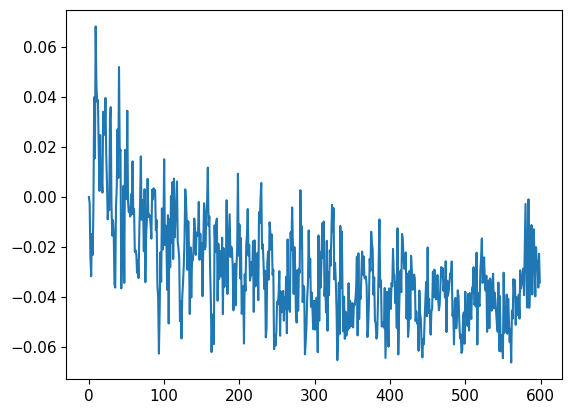

In [27]:
plt.plot(np.array((all_eps_x_per - all_eps_x_per[0]) / all_eps_x_per[0])[:600])

In [11]:
# line_file=list_file_line[0]
# geo_file=list_geo_file[0]
# turn_rcs=list_n_turn[0]

# cumulative_lost_particles=0

# line = xt.Line.from_json(line_file)
# with open(geo_file, 'r') as file:
#     para_file = json.load(file)
# rcs = Geometry(para_file)
# nb_turn_arc = turn_rcs * rcs.nb_arc
# tw1 = line.twiss(method='6d', matrix_stability_tol=0.07, compute_chromatic_properties=True)

# particles = generate_particles(rcs = rcs, line = line, tw = tw1, 
#                                     n_part = n_part, n_turn_rcs = turn_rcs, 
#                                     e_x = nemitt_x_0, e_y = nemitt_y_0, 
#                                     e_s = emit_s, adapt=adapt_ho_delta)

# particles0=particles.copy()
# xplt.PhaseSpacePlot(particles0)


# ramping(rcs, line, method='var_k', t_ref=0, n_turn_rcs=nb_turn_arc, RF_tuning=RF_tuner)
# track_res_1, rec_1 = launch_tracking_mon(line, tw1, turn_rcs, nb_turn_arc, particles, n_part=n_part, plot=True)
# x_mean1, x_mean_log1, y_mean1, y_mean_log1, eps_x_per1, eps_x_std1, eps_x_log1, eps_y_per1, eps_y_std1, eps_y_log1, eps_s_per1, eps_s_std1, eps_s_log1, sig_z1, transmission1 = track_res_1

# transmission, cumulative_lost_particles = calculate_transmission_cumul(
#     particles, n_part, nb_turn_arc, cumulative_lost_particles
# )

# xplt.PhaseSpacePlot(particles)

# particles1=xp.Particles(mass0=xp.MUON_MASS_EV, q0=1, p0c=particles.p0c[0], 
#         x=particles.x, px=particles.px, y=particles.y, py=particles.py,
#         zeta=particles.zeta, delta=particles.delta)

# line_file=list_file_line[1]
# geo_file=list_geo_file[1]
# turn_rcs=list_n_turn[1]

# line = xt.Line.from_json(line_file)
# with open(geo_file, 'r') as file:
#     para_file = json.load(file)
# rcs = Geometry(para_file)
# nb_turn_arc = turn_rcs * rcs.nb_arc
# tw2 = line.twiss(method='6d', matrix_stability_tol=0.07, compute_chromatic_properties=True)

# transfer_matrix(tw1, tw2, particles1)

# ramping(rcs, line, method='var_k', t_ref=0, n_turn_rcs=nb_turn_arc, RF_tuning=RF_tuner)
# track_res_2, rec_2 = launch_tracking_mon(line, tw2, turn_rcs, nb_turn_arc, particles1, n_part=n_part, plot=True)
# x_mean2, x_mean_log2, y_mean2, y_mean_log2, eps_x_per2, eps_x_std2, eps_x_log2, eps_y_per2, eps_y_std2, eps_y_log2, eps_s_per2, eps_s_std2, eps_s_log2, sig_z2, transmission2 = track_res_2

# transmission, cumulative_lost_particles = calculate_transmission_cumul(
#     particles1, n_part, nb_turn_arc, cumulative_lost_particles
# )

# particles1.hide_lost_particles()
# xplt.PhaseSpacePlot(particles1)

# ex=np.concatenate((eps_x_per1,eps_x_per2))
# plt.plot((ex-ex[0])/ex[0])
# plt.show()
# ey=np.concatenate((eps_y_per1,eps_y_per2)
#                   )
# plt.plot((ey-ey[0])/ey[0])
# plt.show()

# es=np.concatenate((eps_s_per1,eps_s_per2)
#                   )
# plt.plot((es-es[0])/es[0])
# plt.show()

In [12]:
# line1 = xt.Line.from_json('/mnt/c/muco/code/lattice/RCS1_DS_inj_5nc.json')
# rcs1 = Geometry('/mnt/c/muco/code/notebook_optics/para_RCS1_opt_5nc.json')
# line2 = xt.Line.from_json('/mnt/c/muco/code/lattice/RCS2_DS_inj.json')
# rcs2 = Geometry('/mnt/c/muco/code/notebook_optics/para_RCS2_opt.json')
# tw1 = line1.twiss(method='6d', matrix_stability_tol=0.07, compute_chromatic_properties=True)
# tw2 = line2.twiss(method='6d', matrix_stability_tol=0.07, compute_chromatic_properties=True)

# segment1 = xt.LineSegmentMap(
#                             length = tw1.s[-1],
#                             qx = tw1.qx, qy = tw1.qy, 
#                             betx = tw1.betx[0], bety = tw1.bety[0],
#                             alfx = tw1.alfx[0], alfy = tw1.alfy[0], 
#                             dx = tw1.dx[0], dpx = 0, #tw1.dpx[0],
#                             dy = tw1.dy[0], dpy = tw1.dpy[0],
#                             x_ref = tw1.x[0], px_ref = tw1.px[0],
#                             y_ref = tw1.y[0], py_ref = tw1.py[0],
#                             longitudinal_mode = 'nonlinear', #'linear_fixed_rf',
#                             momentum_compaction_factor = tw1.momentum_compaction_factor,
#                             voltage_rf = line1['cavity'].voltage*2,
#                             frequency_rf = line1['cavity'].frequency,
#                             lag_rf = line1['cavity'].lag,
#                             energy_ref_increment = line1['RF_acc'].Delta_p0c*2,
#                             energy_increment = line1['RF_acc'].Delta_p0c*2
#                             )

# segment2 = xt.LineSegmentMap(length = tw2.s[-1],
#                             qx = tw2.qx, qy = tw2.qy, 
#                             betx = tw2.betx[0], bety = tw2.bety[0],
#                             alfx = tw2.alfx[0], alfy = tw2.alfy[0], 
#                             dx = tw2.dx[0], dpx = 0, #tw2.dpx[0],
#                             dy = tw2.dy[0], dpy = 0, #tw2.dpy[0],
#                             x_ref = tw2.x[0], px_ref = tw2.px[0],
#                             y_ref = tw2.y[0], py_ref = tw2.py[0],
#                             longitudinal_mode = 'nonlinear', #'linear_fixed_rf',
#                             momentum_compaction_factor = tw2.momentum_compaction_factor,
#                             voltage_rf = line2['cavity'].voltage*2,
#                             frequency_rf = line2['cavity'].frequency,
#                             lag_rf = line2['cavity'].lag,
#                             energy_ref_increment = line2['RF_acc'].Delta_p0c*2,
#                             energy_increment = line2['RF_acc'].Delta_p0c*2
#                             )

# seg_line1 = xt.Line(elements = [segment1],
#                     element_names = ['seg'])
# seg_line1.particle_ref = xt.Particles(p0c=rcs1.injection_energy, mass0=xp.MUON_MASS_EV)
# tw_seg1 = seg_line1.twiss(method='6d', matrix_stability_tol=0.07, compute_chromatic_properties=True)

# seg_line2 = xt.Line(elements = [segment2],
#                     element_names = ['seg'])
# seg_line2.particle_ref = xt.Particles(p0c=rcs2.injection_energy, mass0=xp.MUON_MASS_EV)
# tw_seg2 = seg_line2.twiss(method='6d', matrix_stability_tol=0.07, compute_chromatic_properties=True)

# list_line=[seg_line1, seg_line2]
# list_rcs=[rcs1,rcs2]
# list_n_turn=[17,55
#             #  ,66,55
#              ]

# plot=True
# rec_rcs = []
# # Lists to store the concatenated data from all RCS
# all_x_mean, all_y_mean = [], []
# all_x_mean_log, all_y_mean_log = [], []
# all_eps_x_per, all_eps_y_per, all_eps_s_per = [], [], []
# all_eps_x_std, all_eps_y_std, all_eps_s_std = [], [], []
# all_eps_x_log, all_eps_y_log, all_eps_s_log = [], [], []
# all_sig_z, all_transmission = [], []
# all_turns = []

# rcs_boundaries = np.cumsum(list_n_turn)
# cumulative_turns = 0
# cumulative_lost_particles = 0  # Track cumulative lost particles across RCS

# for i_RCS, (line, rcs, turn_rcs) in enumerate(zip(list_line, list_rcs, list_n_turn)):
#     print(f'RCS {i_RCS}')
#     # Load the line and geometry
#     nb_turn_arc = turn_rcs * rcs.nb_arc
#     tw = line.twiss(method='6d', matrix_stability_tol=0.07, compute_chromatic_properties=True)

#     # Generate particles for the first RCS only
#     if i_RCS == 0:
#         print('Generate initial particle distribution')
#         particles = generate_particles(rcs = rcs, line = line, tw = tw, 
#                                     n_part = n_part, n_turn_rcs = turn_rcs, 
#                                     e_x = nemitt_x_0, e_y = nemitt_y_0, 
#                                     e_s = emit_s, adapt=adapt_ho_delta)

#     else:
#         particles0=particles.copy()
#         mask_lost = particles0.state > 0
#         particles=xp.Particles(
#                 mass0=xp.MUON_MASS_EV, q0=1, p0c=particles0.p0c[mask_lost][0],
#                 x=particles0.x[mask_lost], px=particles0.px[mask_lost], 
#                 y=particles0.y[mask_lost], py=particles0.py[mask_lost],
#                 zeta=particles0.zeta[mask_lost], delta=particles0.delta[mask_lost]
#                 )
#         print('RCS1 bet', tw_previous.betx[0], tw_previous.bety[0])
#         print('RCS2 bet', tw.betx[0], tw.bety[0])
#         cov=np.cov(particles.x, particles.px)
#         eps=np.sqrt(np.linalg.det(cov))
#         betx = cov[0, 0] / eps
#         cov=np.cov(particles.y, particles.py)
#         eps=np.sqrt(np.linalg.det(cov))
#         bety = cov[0, 0] / eps
#         print('Particles bet bf transfer matrix', betx, bety)
#         transfer_matrix(tw_previous, tw, particles)
#         cov=np.cov(particles.x, particles.px)
#         eps=np.sqrt(np.linalg.det(cov))
#         betx = cov[0, 0] / eps
#         cov=np.cov(particles.y, particles.py)
#         eps=np.sqrt(np.linalg.det(cov))
#         bety = cov[0, 0] / eps
#         print('Particles bet bf transfer matrix', betx, bety)

#     particles.hide_lost_particles()
#     # calc_separatrix(line=line, rcs=rcs, tw=tw, particles=particles,
#                 # title= f'RF bucket at injection in RCS{i_RCS+1}')

#     # Track for the current RCS
#     track_res, rec = launch_tracking_mon(line = line, tw = tw, n_turn_rcs = turn_rcs, 
#                     nb_turn_arc = nb_turn_arc, particles = particles, n_part=n_part, plot=False)

#     rec_rcs.append(rec)

#     # Aggregate the data for plotting
#     x_mean, x_mean_log, y_mean, y_mean_log, eps_x_per, eps_x_std, eps_x_log, eps_y_per, eps_y_std, eps_y_log, eps_s_per, eps_s_std, eps_s_log, sig_z, transmission = track_res

#     # Calculate overall transmission with cumulative particle loss
#     transmission, cumulative_lost_particles = calculate_transmission_cumul(
#         particles, n_part, nb_turn_arc, cumulative_lost_particles
#     )

#     # Append data for the current RCS
#     all_x_mean.extend(x_mean)
#     all_x_mean_log.extend(x_mean_log)
#     all_y_mean.extend(y_mean)
#     all_y_mean_log.extend(y_mean_log)
#     all_eps_x_per.extend(eps_x_per)
#     all_eps_x_std.extend(eps_x_std)
#     all_eps_x_log.extend(eps_x_log)
#     all_eps_y_per.extend(eps_y_per)
#     all_eps_y_std.extend(eps_y_std)
#     all_eps_y_log.extend(eps_y_log)
#     all_eps_s_per.extend(eps_s_per)
#     all_eps_s_std.extend(eps_s_std)
#     all_eps_s_log.extend(eps_s_log)

#     all_sig_z.extend(sig_z)
#     all_transmission.extend(transmission)
    
#     particles.hide_lost_particles()
#     xplt.PhaseSpacePlot(particles)
#     tw_previous = tw

#     # Generate the x axis for each rcs
#     all_turns.append(np.linspace(cumulative_turns, cumulative_turns + turn_rcs, turn_rcs * rcs.nb_arc))
#     cumulative_turns += turn_rcs
#     # calc_separatrix(line=line, rcs=rcs, tw=tw, particles=particles,
#     #                 title= f'RF bucket at exctraction in RCS{i_RCS+1}')

# # result_rcs = [all_x_mean, all_y_mean, all_eps_x_per, all_eps_x_std, all_eps_y_per, all_eps_y_std,
# #             all_eps_s, all_sig_z, all_transmission]
# # Concatenate all 
# all_turns = np.concatenate(all_turns)

# if plot:
#     plt.figure(figsize=(7, 5))
#     ax1 = plt.subplot(2, 1, 1)
#     plt.ylabel(r'$\Delta \epsilon_x / \epsilon_{x,0}$')
#     plt.plot(all_turns, (np.array(all_eps_x_per) - all_eps_x_per[0]) / all_eps_x_per[0], label='per', color='tab:blue')
#     # plt.plot(all_turns, (np.array(all_eps_x_std) - all_eps_x_std[0]) / all_eps_x_std[0], label='std', color='tab:green')
#     # plt.plot(all_turns, (np.array(all_eps_x_log) - all_eps_x_log[0]) / all_eps_x_log[0], label='log', color='tab:orange')
#     plt.legend()
#     # plt.ylim(-0.01,0.06)
#     for boundary in rcs_boundaries:
#         ax1.axvline(boundary, color='red', linestyle='--', alpha=0.6)

#     ax2 = plt.subplot(2, 1, 2, sharex=ax1)
#     plt.ylabel(r'$\Delta \epsilon_y /\epsilon_{y,0}$')
#     plt.plot(all_turns, (np.array(all_eps_y_per) - all_eps_y_per[0]) / all_eps_y_per[0], label='per', color='tab:blue')
#     # plt.plot(all_turns, (np.array(all_eps_y_std) - all_eps_y_std[0]) / all_eps_y_std[0], label='std', color='tab:green')
#     # plt.plot(all_turns, (np.array(all_eps_y_log) - all_eps_y_log[0]) / all_eps_y_log[0], label='log', color='tab:orange')
#     plt.legend()
#     for boundary in rcs_boundaries:
#         ax2.axvline(boundary, color='red', linestyle='--', alpha=0.6)
#     plt.xlabel('Turn')
#     plt.tight_layout()
#     plt.show()

#     # Plot for longitudinal emittance and transmission
#     plt.figure(figsize=(7, 5))
#     ax1 = plt.subplot(2, 1, 1)
#     plt.ylabel(r'$\Delta \epsilon_s / \epsilon_{s,0}$')
#     plt.plot(all_turns, (np.array(all_eps_s_per) - all_eps_s_per[0]) / all_eps_s_per[0], label='per', color='tab:blue')
#     # plt.plot(all_turns, (np.array(all_eps_s_std) - all_eps_s_std[0]) / all_eps_s_std[0], label='std', color='tab:green')
#     # plt.plot(all_turns, (np.array(all_eps_s_log) - all_eps_s_log[0]) / all_eps_s_log[0], label='log', color='tab:orange')

#     plt.legend()
#     for boundary in rcs_boundaries:
#         ax1.axvline(boundary, color='red', linestyle='--', alpha=0.6)

#     ax2 = plt.subplot(2, 1, 2, sharex=ax1)
#     plt.ylabel('Transmission')
#     plt.plot(all_turns, all_transmission, color='tab:blue')
#     for boundary in rcs_boundaries:
#         ax2.axvline(boundary, color='red', linestyle='--', alpha=0.6)
#     plt.xlabel('Turn')
#     plt.tight_layout()
#     plt.show()

In [13]:
# r2=rec_rcs[1]
# # for i in range (0, len(r2.x[0,:]), 26*10):
# i=26*45
# mask= r2.state[:,int(i)] == 1
# zeta = r2.zeta[:,int(i)]
# delta = r2.delta[:,int(i)]
# plt.scatter(zeta[mask], delta[mask], s=1)
# # plt.ylim(-0.02,0.02)    
# # plt.xlim(-0.05,0.05)

# r1=rec_rcs[0]
# plt.scatter(r1.zeta[:,0], r1.delta[:,0], s=1)
# plt.scatter(r1.zeta[:,-1], r1.delta[:,-1], s=1)
# plt.show()
# r2=rec_rcs[1]
# plt.scatter(r2.zeta[:,0], r2.delta[:,0], s=1)
# plt.scatter(r2.zeta[:,60], r2.delta[:,60], s=1)
# plt.show()

# plt.figure()
# plt.plot(tw1.s,tw1.betx, label='betx')
# plt.plot(tw_seg1.s, tw_seg1.betx)
# plt.plot(tw1.s, tw1.bety, label='bety')
# plt.plot(tw_seg1.s, tw_seg1.bety)
# plt.plot(tw1.s,tw1.dx, label='Dx')
# plt.plot(tw_seg1.s,tw_seg1.dx, label='Dx')

# # plt.plot(tw1.s, tw1.dy, label='Dy')
# plt.show()

# plt.figure()
# plt.plot(tw2.s,tw2.betx, label='betx')
# plt.plot(tw2.s, tw2.bety, label='bety')
# plt.plot(tw2.s, tw2.dx, label='Dx')
# plt.plot(tw2.s, tw2.dy, label='Dy')
# plt.show()

In [14]:
# all_t_acc = np.insert(all_t_acc, 0, 0)
# rcs_boundaries = np.insert(rcs_boundaries, 0, 0)
# # Set up a 4-row subplot layout (1 column)
# fig, axs = plt.subplots(4, 1, figsize=(7, 10), sharex=True)

# # Plot for transverse emittance in x-direction (eps_x)
# axs[0].set_ylabel(r'$\Delta \epsilon_x / \epsilon_{x,0}$')
# axs[0].plot(all_turns, (np.array(all_eps_x_per) - all_eps_x_per[0]) / all_eps_x_per[0], label='per', color='tab:blue')
# for boundary in rcs_boundaries:
#     axs[0].axvline(boundary, color='darkred', linestyle='--')

# # Plot for transverse emittance in y-direction (eps_y)
# axs[1].set_ylabel(r'$\Delta \epsilon_y / \epsilon_{y,0}$')
# axs[1].plot(all_turns, (np.array(all_eps_y_per) - all_eps_y_per[0]) / all_eps_y_per[0], label='per', color='tab:blue')
# for boundary in rcs_boundaries:
#     axs[1].axvline(boundary, color='darkred', linestyle='--')

# # Plot for longitudinal emittance (eps_s)
# axs[2].set_ylabel(r'$\Delta \epsilon_s / \epsilon_{s,0}$')
# axs[2].plot(all_turns, (np.array(all_eps_s_per) - all_eps_s_per[0]) / all_eps_s_per[0], label='per', color='tab:blue')
# for boundary in rcs_boundaries:
#     axs[2].axvline(boundary, color='darkred', linestyle='--')

# # Plot for transmission
# axs[3].set_ylabel('Transmission')
# axs[3].plot(all_turns, all_transmission, color='tab:blue')
# for boundary in rcs_boundaries:
#     axs[3].axvline(boundary, color='darkred', linestyle='--')

# # Add secondary x-axis (for acceleration time) with RCS labels
# secax = axs[3].secondary_xaxis('bottom')
# secax.spines['bottom'].set_position(('outward', 40))  # Move secondary axis outward by 40 points
# secax.set_xticks(rcs_boundaries)
# secax.set_xticklabels([f"{t*1e3:.2f}" for t in all_t_acc])
# secax.set_xlabel('Acceleration Time (ms)', color='darkred')
# secax.tick_params(axis='x', colors='darkred')
# secax.spines['bottom'].set_color('darkred')

# # Set common xlabel for the entire figure
# axs[3].set_xlabel('RCS Turn')

# # Add RCS labels between the boundaries on the top of the figure
# for i in range(len(rcs_boundaries) - 1):
#     x_mid = (rcs_boundaries[i] + rcs_boundaries[i + 1]) / 2
#     axs[0].text(x_mid, axs[0].get_ylim()[1] * 1.08, f'RCS {i + 1}', 
#                 ha='center', va='center', fontsize=11, color='darkred')

# # Finalize the layout and display
# plt.tight_layout()
# plt.show()

In [15]:
# line_file='/mnt/c/muco/code/lattice/RCS1_DS_inj_5nc.json'
# line = xt.Line.from_json(line_file)
# tw = line.twiss(method='6d', matrix_stability_tol=0.07, compute_chromatic_properties=True)
# def to_norm(x, px):
#     x_norm = x / np.sqrt(tw['betx'][0])
#     px_norm = x *tw['alfx'][0]/np.sqrt(tw['betx'][0]) + np.sqrt(tw['betx'][0])*px
#     return x_norm, px_norm

In [16]:
def track_start_end(list_file_line, list_geo_file, list_n_turn, plot=True):
    
    rec_rcs = []
    # Lists to store the concatenated data from all RCS
    all_x_mean, all_y_mean = [], []
    all_eps_x, all_eps_y, all_eps_s = [], [], []
    all_sig_z, all_transmission = [], []
    all_turns = []

    rcs_boundaries = np.cumsum(list_n_turn)
    cumulative_lost_particles = 0  # Track cumulative lost particles across RCS

    for i_RCS, (line_file, geo_file, turn_rcs) in enumerate(zip(list_file_line, list_geo_file, list_n_turn)):
        print(f'RCS {i_RCS+1}')
        # Load the line and geometry
        line = xt.Line.from_json(line_file)
        with open(geo_file, 'r') as file:
            para_file = json.load(file)
        rcs = Geometry(para_file)
        nb_turn_arc = turn_rcs * rcs.nb_arc
        tw = line.twiss(method='6d', matrix_stability_tol=0.07, compute_chromatic_properties=True)

        # Generate particles for the first RCS only
        if i_RCS == 0:
            particles = generate_particles(rcs = rcs, line = line, tw = tw, 
                                        n_part = n_part, n_turn_rcs = turn_rcs, 
                                        e_x = nemitt_x_0, e_y = nemitt_y_0, 
                                        e_s = emit_s, adapt=adapt_ho_delta)
        else:
            # particles.reorganize()
            print( len(particles.x[particles.state<0]) )
        
        # Apply ramping for the current RCS
        ramping(rcs, line, method='var_k', t_ref=0, n_turn_rcs=nb_turn_arc, RF_tuning=RF_tuner)
        
        # Track for the current RCS
        # track_res, rec = launch_tracking_mon(line, tw, nb_turn_arc, particles,n_part=n_part, plot=False)
        track_res, rec = launch_tracking(line, nb_turn_arc, particles,n_part=n_part, plot=False)
        # Store the results for this RCS
        rec_rcs.append(rec)
        
        # Aggregate the data for plotting
        x_mean, y_mean, eps_x, eps_y, eps_s, sig_z, transmission = track_res
        
        # Calculate overall transmission with cumulative particle loss
        lost_part = particles.at_turn[particles.state < 0]
        transmission, cumulative_lost_particles = calculate_transmission_cumul(
            sorted(lost_part), n_part, nb_turn_arc, cumulative_lost_particles
        )
        
        # Append data for the current RCS
        all_x_mean.extend(x_mean)
        all_y_mean.extend(y_mean)
        all_eps_x.extend(eps_x)
        all_eps_y.extend(eps_y)
        all_eps_s.extend(eps_s)
        all_sig_z.extend(sig_z)
        all_transmission.extend(transmission)

        particles.hide_lost_particles()
        xplt.PhaseSpacePlot(particles)
        # particles.unhide_lost_particles()


    result_rcs = [all_x_mean, all_y_mean, all_eps_x, all_eps_y, 
                    all_eps_s, all_sig_z, all_transmission]
    all_turns=np.linspace(0, np.sum(list_n_turn), len(all_x_mean))

    # Plotting aggregated results across all RCS
    if plot:
        # Plot for horizontal and vertical emittance evolution
        plt.figure(figsize=(7, 5))
        ax1 = plt.subplot(2, 1, 1)
        plt.ylabel(r'$\Delta \epsilon_x / \epsilon_{x,0}$')
        plt.plot(all_turns, (np.array(all_eps_x) - all_eps_x[0]) / all_eps_x[0], alpha=0.8, color='tab:blue')
        for boundary in rcs_boundaries:
            ax1.axvline(boundary, color='red', linestyle='--', alpha=0.6)

        ax2 = plt.subplot(2, 1, 2, sharex=ax1)
        plt.ylabel(r'$\Delta \epsilon_y /\epsilon_{y,0}$')
        plt.plot(all_turns, (np.array(all_eps_y) - all_eps_y[0]) / all_eps_y[0], alpha=0.8, color='tab:blue')
        for boundary in rcs_boundaries:
            ax2.axvline(boundary, color='red', linestyle='--', alpha=0.6)
        plt.xlabel('Turn')
        plt.tight_layout()
        plt.show()

        # Plot for longitudinal emittance and transmission
        plt.figure(figsize=(7, 5))
        ax1 = plt.subplot(2, 1, 1)
        plt.ylabel(r'$\Delta \epsilon_s / \epsilon_{s,0}$')
        plt.plot(all_turns, (np.array(all_eps_s) - all_eps_s[0]) / all_eps_s[0], color='tab:blue')
        for boundary in rcs_boundaries:
            ax1.axvline(boundary, color='red', linestyle='--', alpha=0.6)

        ax2 = plt.subplot(2, 1, 2, sharex=ax1)
        plt.ylabel('Transmission')
        plt.plot(all_turns, all_transmission, color='tab:blue')
        for boundary in rcs_boundaries:
            ax2.axvline(boundary, color='red', linestyle='--', alpha=0.6)
        plt.xlabel('Turn')
        plt.tight_layout()
        plt.show()

        return result_rcs, rec_rcs

In [17]:
# result_rcs, rec_rcs = track_start_end(list_file_line, list_geo_file, list_n_turn, plot=True)

In [18]:
# all_x_mean, all_y_mean, all_eps_x, all_eps_y, all_eps_s, all_sig_z, all_transmission = result_rcs